In [1]:
cd ./wrkDir/s18-2/

/work/xiangchong.li/work/S18ASimHSC/s18-2


In [25]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import scipy.optimize as opt
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt
cm  = plt.cm.get_cmap('RdYlBu')

import logging
logging.basicConfig(filename='4-ReGaus_Calib.log',level=logging.INFO)

anaDir='./anaCat'
pltDir='./plot/calibration'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

# Blinding parameters
add_m_val=0.
add_a_val=0.

Populating the interactive namespace from numpy and matplotlib


# Determine snr-res slide grids

In [3]:
# Read catalog
dataF =   pd.read_hdf(inFname)
dataO=dataF.to_records(index=True)
# Apply WL cut for simulations
# NOTE: We are using numpy record to do the selection
# TODO: Use pandas.DataFrame based in the future
min_snr=10
max_snr=80
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

# Whether to remove selection bias
force_90_pair=True

wlmask    =   utilities.galaxy_selector(catalog=dataO,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=force_90_pair,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
data=dataO[wlmask]
del dataO

In [4]:
# Prepare the SNR resolution bins
force_weight=True
ngal_bin=20*100*100
nbin_1d=8

# We need to get the weight here, to use when averaging over galaxies to get mean effective
# SNR and resolution.
# Note, it might be worth making a utility for this combined shape + S16A weight, since it's
# done here and in estimate_subfield_shear.
shape_weight = utilities.get_weight_model(data)*data['weight']
if force_weight:
    shape_weight[1::2] = shape_weight[0::2]
snr=utilities.get_snr(data)
res=utilities.get_res(data)
snr_lower, snr_upper, res_lower, res_upper = \
    utilities.sliding_window_def(snr,res,shape_weight,
    n_gal=ngal_bin,n_bin_1d=nbin_1d)

slide_ibins=np.ones(len(data))*-1
snr_bins = np.zeros((nbin_1d, nbin_1d))
res_bins = np.zeros((nbin_1d, nbin_1d))
# Record the mean (snr,res) for each bin
for j in range(nbin_1d):
    for k in range(nbin_1d):
        tmp_mask = (snr >= snr_lower[j]) & (snr < snr_upper[j]) & \
        (res >= res_lower[j,k]) & (res < res_upper[j,k])
        if force_90_pair:
            tmp_mask[1::2] = tmp_mask[0::2]
        slide_ibins[tmp_mask]=j*nbin_1d+k
        mean_snr = np.sum(shape_weight[tmp_mask]*snr[tmp_mask])/ \
            np.sum(shape_weight[tmp_mask])
        mean_res = np.sum(shape_weight[tmp_mask]*res[tmp_mask])/ \
            np.sum(shape_weight[tmp_mask])
        snr_bins[j,k] = mean_snr
        res_bins[j,k] = mean_res
fake_x = np.vstack((snr_bins.flatten(), res_bins.flatten()))

dataF['calib_slide_ibins']=np.ones(len(wlmask))*-1.
dataF['calib_slide_ibins'][wlmask]=slide_ibins
dataF['wlmask_90rot']=wlmask
dataF.to_hdf(inFname,key='data')

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy


Text(0.5, 1.0, 'Slide Grid')

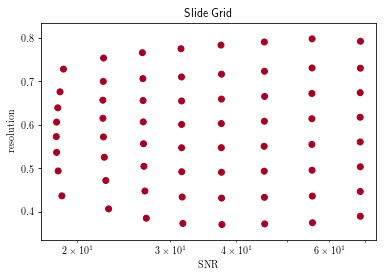

In [7]:
plt.scatter(snr_bins, res_bins, c=np.ones(res_bins.shape), cmap=cm)
plt.xscale('log')
plt.xlabel(r'\rm{SNR}')
plt.ylabel(r'\rm{resolution}')
plt.title('Slide Grid')

# Calibration
## Multiplicative bias and Additive bias

In [11]:
# Load outcomes of reGaus_shearCalib.py
shearBinName=   os.path.join(pltDir,'shear_slide_bins_force_weight.npy')
outcomes=np.load(shearBinName)


In [17]:
nsim   =   len(outcomes)
psf_e1 =   np.zeros(nsim)
psf_e2 =   np.zeros(nsim)
weight =   np.zeros(nsim)
g1_true=   np.zeros(nsim)
g2_true=   np.zeros(nsim)
g1_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
g2_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
sigma_g_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
dshape =   (nbin_1d,nbin_1d)

for iout,outcome in enumerate(outcomes):
    g1_true[iout]  =   outcome[0]
    g2_true[iout]  =   outcome[1]
    g1_bins[:,:,iout]  =   outcome[2]
    g2_bins[:,:,iout]  =   outcome[3]
    sigma_g_bins[:,:,iout]  =   outcome[4]
    psf_e1[iout]  =   outcome[5]
    psf_e2[iout]  =   outcome[6]
    weight[iout]  =   outcome[7]

m1_bins    =   np.zeros(dshape)
a1_bins    =   np.zeros(dshape)
sigm1_bins =   np.zeros(dshape)
siga1_bins =   np.zeros(dshape)

# For each of the sliding bins in SNR/resolution.
for j in range(nbin_1d):
    for k in range(nbin_1d):
        # divide sigma by sqrt(N)
        sigma_vals = sigma_g_bins[j,k,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e10)
        # get multiplicative bias and additive bias
        m1_bins[j,k],a1_bins[j,k], \
        sigm1_bins[j,k],siga1_bins[j,k]= \
            utilities.get_m_c_a(g1_bins[j,k,tmp_use],
                                g2_bins[j,k,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
        logging.info('Bin %d %d bias analysis:'%(j,k))
        logging.info('m = %.3f +/- %.3f' % (m1_bins[j,k], sigm1_bins[j,k]))
        logging.info('a = %.3f +/- %.3f' % (a1_bins[j,k], siga1_bins[j,k]))
        
if not force_weight:
    shearName   =   os.path.join(pltDir,'shear_m_a_2d.csv')
    shearTab    =   Table.read(shearName)
    m1_bins-= np.array(shearTab['m']).reshape(dshape)
    a1_bins-= np.array(shearTab['a']).reshape(dshape)

#Write data
out_data    =   list(zip(snr_bins.flatten(), res_bins.flatten(),
        m1_bins.flatten(), sigm1_bins.flatten(),
        a1_bins.flatten(), siga1_bins.flatten()))

if force_weight:
    prefix='shear'
else:
    prefix='weightBias'

biasBinFname    =   os.path.join(pltDir,'%s_m_a_2d.csv' %(prefix))
mcBinTab    =   pd.DataFrame(data=out_data,columns=('snr','res','m','mSigma','a','aSigma'))
mcBinTab.to_csv(biasBinFname)

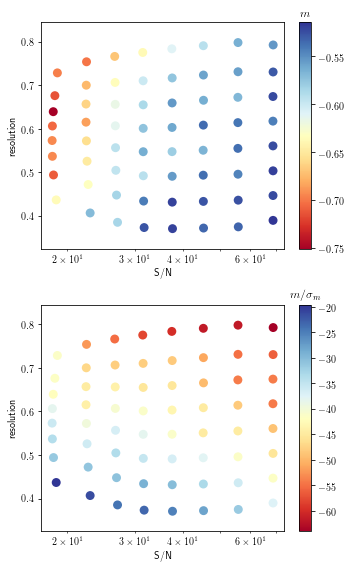

In [19]:
#Plot bias in each bins
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m1_bins+add_m_val, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
if add_m_val > 0:
    cbar.ax.set_title(r'$m+$constant')
else:
    cbar.ax.set_title(r'$m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=m1_bins/sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m/\sigma_m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.tight_layout()
#plt.savefig(pltDir+'%s_m_2d.png'%(prefix))

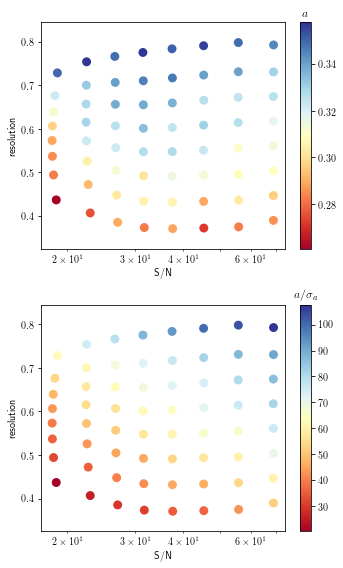

In [26]:
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=a1_bins+add_a_val, cmap=cm,vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
if add_a_val > 0:
    cbar.ax.set_title(r'$m+$constant')
else:
    cbar.ax.set_title(r'$a$' )
# Also plot errors in this case.
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=a1_bins/siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a/\sigma_a$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.tight_layout()
#plt.savefig(pltDir+'%s_a_2d.png'%(prefix))

In [27]:
# Fitting
outMA   =   {}

# Model fitting for multiplicative bias
m_opt, m_cov = opt.curve_fit(
    utilities.m_func, fake_x, m1_bins.flatten(), sigma=sigm1_bins.flatten(),
    bounds=([-np.inf,0,-np.inf,-np.inf],[np.inf,np.inf,0,np.inf]))

outMA.update({'m_opt':m_opt,'m_cov':m_cov})
print('m model:')
print('m=b*(res/0.5)^c*(snr/20)^d+e')
for ind in range(len(m_opt)):
    print('%f +/- %f'%(m_opt[ind],m_cov[ind,ind]))

# For additive bias
a_opt, a_cov = opt.curve_fit(
    utilities.a_func, fake_x, a1_bins.flatten(), sigma=siga1_bins.flatten(),
    bounds=([-np.inf,-np.inf,-np.inf],[np.inf,np.inf,0.]))

outMA.update({'a_opt':a_opt,'a_cov':a_cov})
print('a model:')
print('a=b*(res-c)*(snr/20)^d')
for ind in range(len(a_opt)):
    print('%f +/- %f'%(a_opt[ind],a_cov[ind,ind]))

# Save results
maFname  =   pltDir+'%s_m_a_model_par.npy'%(prefix)
np.save(maFname,outMA)

m model:
m=b*(res/0.5)^c*(snr/20)^d+e
-0.147597 +/- 0.000197
1.133953 +/- 0.035998
-1.391906 +/- 0.029869
-0.496082 +/- 0.000124
a model:
a=b*(res-c)*(snr/20)^d
0.156975 +/- 0.000083
-1.459002 +/- 0.014509
-0.006918 +/- 0.000064


Text(0, 0.5, 'resolution')

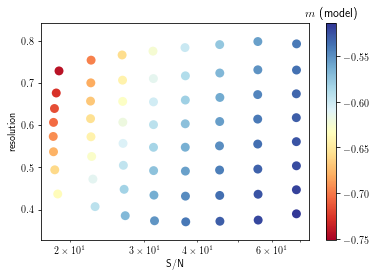

In [31]:
# Plot the bias model
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
m_opt   =   outMA['m_opt']
a_opt   =   outMA['a_opt']
# plot the model, residuals, and their significance
m_model =   utilities.m_func(fake_x, *m_opt).reshape(dshape)
deltaM  =   m1_bins-m_model


fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=m_model, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ (model)')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
#plt.savefig(pltDir+'%s_m_model_2d.png'%(prefix))

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=deltaM,
            cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins,
            c=(m1_bins-m_model)/sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($m$ - model)/$\sigma_m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
#plt.savefig(pltDir+'%s_m_model_signif_2d.png'%(prefix))

In [ ]:
# Plot model, residuals, significance
a_model = utilities.a_func(fake_x, *a_opt).reshape(nbin_1d, nbin_1d)
deltaA  =   a1_bins-a_model
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=a_model, cmap=cm,
            vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ (model)')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
#plt.savefig(pltDir+'%s_a_model_2d.png'%(prefix))

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins,res_bins,c=deltaA,
                cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
#plt.savefig(pltDir+'%s_Delta_a_model_2d.png'%(prefix))

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins,
            c=(a1_bins-a_model)/siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($a$ - model)/$\sigma_a$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
#plt.savefig(pltDir+'%s_a_model_signif_2d.png'%(prefix))

out_data=(snr_bins.flatten(), res_bins.flatten(),
        deltaM.flatten(), sigm1_bins.flatten(),
        deltaA.flatten(), siga1_bins.flatten())
mcDeltaBinTab    =   Table(data=out_data,names=('snr','res','dm','mSigma','da','aSigma'))
mcDeltaBinTab.write(pltDir+'%s_dm_da_2d.csv'%(prefix))

## Weight Bias

## Selection Bias